# Experiment 1: Time and frequency domain, and the pendulum
CSAI4014 AISR lab. Builds a known three-tone signal, reads its spectrum, demonstrates
aliasing, and integrates the damped pendulum. Every figure is saved to `figs/` and every
number that goes into the report is saved to `results.json`.

In [1]:
import json, os
import numpy as np
import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

os.makedirs('figs', exist_ok=True)
mpl.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
                     'font.size': 10, 'axes.grid': True, 'grid.color': '0.88', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.4,
                     'legend.frameon': False, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']   # fixed categorical order
print('numpy', np.__version__, '| scipy', scipy.__version__, '| matplotlib', mpl.__version__)
R = {}   # results collected for the report

numpy 1.26.4 | scipy 1.16.1 | matplotlib 3.10.5


## 1. Sampling parameters and the constructed signal

N = 1000, df = 0.5 Hz, Nyquist = 250.0 Hz


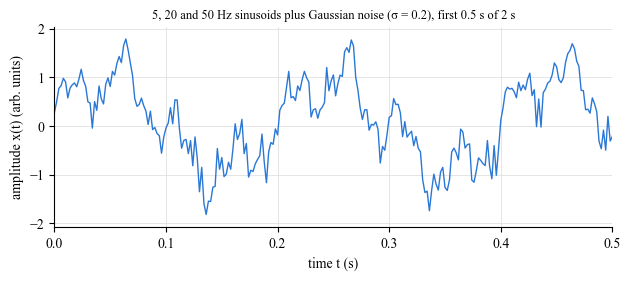

In [2]:
fs, T = 500.0, 2.0                         # sampling rate (Hz), record length (s)
t = np.arange(0, T, 1/fs)
N = t.size
df = fs / N                                # frequency resolution (Hz)
f_set = [5.0, 20.0, 50.0]
a_set = [1.00, 0.50, 0.25]

rng = np.random.default_rng(500119608 % 1000)   # seeded from my SAP ID: reproducible
x = sum(a*np.sin(2*np.pi*f*t) for f, a in zip(f_set, a_set)) + 0.20*rng.standard_normal(N)
print(f'N = {N}, df = {df} Hz, Nyquist = {fs/2} Hz')
R['sampling'] = dict(fs=fs, T=T, N=N, df=df, nyquist=fs/2)

fig, ax = plt.subplots(figsize=(7.2, 2.6))
ax.plot(t, x, color=C[0], lw=1.0)
ax.set_xlim(0, 0.5)
ax.set_xlabel('time t (s)'); ax.set_ylabel('amplitude x(t) (arb. units)')
ax.set_title('5, 20 and 50 Hz sinusoids plus Gaussian noise (σ = 0.2), first 0.5 s of 2 s', fontsize=9)
fig.savefig('figs/fig1_1_signal.png'); plt.show()

## 2. One-sided amplitude spectrum

set   5.0 Hz -> peak at  5.00 Hz, amplitude 1.007
set  20.0 Hz -> peak at 20.00 Hz, amplitude 0.496
set  50.0 Hz -> peak at 50.00 Hz, amplitude 0.246
T=1.7 s: 5.0 Hz -> 4.706 Hz, amp 0.661, 6 bins above 10% of peak
T=1.7 s: 20.0 Hz -> 20.000 Hz, amp 0.495, 1 bins above 10% of peak
T=1.7 s: 50.0 Hz -> 50.000 Hz, amp 0.236, 1 bins above 10% of peak


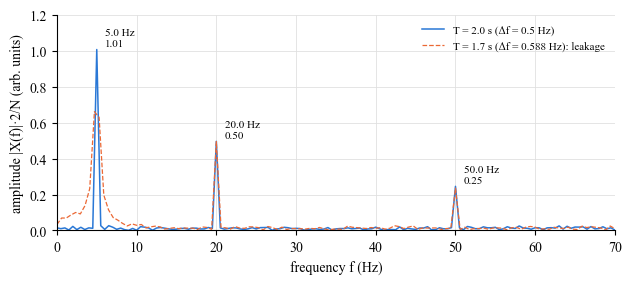

In [3]:
def amplitude_spectrum(sig, fs):
    """One-sided amplitude spectrum scaled so a peak height equals the sine amplitude."""
    X = np.fft.rfft(sig)
    f = np.fft.rfftfreq(sig.size, d=1/fs)
    amp = np.abs(X) * 2.0 / sig.size
    amp[0] /= 2.0                           # the DC term is not doubled
    return f, amp

f, amp = amplitude_spectrum(x, fs)
measured = []
for fset in f_set:                          # strongest bin within +-2 Hz of each set frequency
    win = (f > fset - 2) & (f < fset + 2)
    k = np.flatnonzero(win)[np.argmax(amp[win])]
    measured.append((float(f[k]), float(amp[k])))
    print(f'set {fset:5.1f} Hz -> peak at {f[k]:5.2f} Hz, amplitude {amp[k]:.3f}')
R['spectrum'] = [dict(set_f=fs_, set_a=a_, meas_f=mf, meas_a=ma)
                 for fs_, a_, (mf, ma) in zip(f_set, a_set, measured)]
R['noise_floor_mean'] = float(np.mean(amp[(f > 60)]))

# Spectral leakage: same signal with T = 1.7 s (frequencies no longer on bin centres)
T2 = 1.7
t2 = np.arange(0, T2, 1/fs)
x2 = sum(a*np.sin(2*np.pi*fq*t2) for fq, a in zip(f_set, a_set)) + 0.20*rng.standard_normal(t2.size)
f2, amp2 = amplitude_spectrum(x2, fs)
leak = []
for fset in f_set:
    win = (f2 > fset - 2) & (f2 < fset + 2)
    k = np.flatnonzero(win)[np.argmax(amp2[win])]
    above = int(np.sum(amp2[win] > 0.1*amp2[k]))   # bins above 10 % of the peak
    leak.append(dict(set_f=fset, peak_f=float(f2[k]), peak_a=float(amp2[k]), bins_above_10pct=above))
    print(f'T=1.7 s: {fset} Hz -> {f2[k]:.3f} Hz, amp {amp2[k]:.3f}, {above} bins above 10% of peak')
R['leakage'] = dict(T=T2, df=fs/t2.size, peaks=leak)

fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.plot(f, amp, color=C[0], lw=1.1, label='T = 2.0 s (Δf = 0.5 Hz)')
ax.plot(f2, amp2, color=C[1], lw=0.9, ls='--', label='T = 1.7 s (Δf = 0.588 Hz): leakage')
for (mf, ma) in measured:
    ax.annotate(f'{mf:.1f} Hz\n{ma:.2f}', (mf, ma), xytext=(6, 2), textcoords='offset points', fontsize=8)
ax.set_xlim(0, 70); ax.set_ylim(0, 1.2)
ax.set_xlabel('frequency f (Hz)'); ax.set_ylabel('amplitude |X(f)|·2/N (arb. units)')
ax.legend(loc='upper right', fontsize=8)
fig.savefig('figs/fig1_2_spectrum.png'); plt.show()

## 3. Aliasing: a 5 Hz sine sampled at 8 Hz

Nyquist = 4.0 Hz; peak at 3.0 Hz (expected |8 - 5| = 3 Hz)


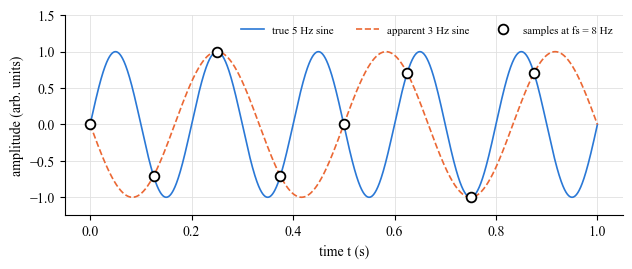

In [4]:
fs_a = 8.0                                  # deliberately below 2 x 5 Hz
t_a = np.arange(0, 1.0, 1/fs_a)
x_a = np.sin(2*np.pi*5*t_a)
f_a, amp_a = amplitude_spectrum(x_a, fs_a)
alias_peak = float(f_a[np.argmax(amp_a)])
print('Nyquist =', fs_a/2, 'Hz; peak at', alias_peak, 'Hz (expected |8 - 5| = 3 Hz)')
R['alias_peak'] = alias_peak

tt = np.linspace(0, 1, 2000)
fig, ax = plt.subplots(figsize=(7.2, 2.6))
ax.plot(tt, np.sin(2*np.pi*5*tt), color=C[0], lw=1.2, label='true 5 Hz sine')
ax.plot(tt, -np.sin(2*np.pi*3*tt), color=C[1], lw=1.2, ls='--', label='apparent 3 Hz sine')
ax.plot(t_a, x_a, 'o', ms=7, mfc='white', mec='k', mew=1.3, label='samples at fs = 8 Hz')
ax.set_xlabel('time t (s)'); ax.set_ylabel('amplitude (arb. units)')
ax.legend(loc='upper right', fontsize=8, ncol=3)
ax.set_ylim(-1.25, 1.5)
fig.savefig('figs/fig1_3_aliasing.png'); plt.show()

## 4. The pendulum: damping and the phase portrait

T0 = 2.0061 s


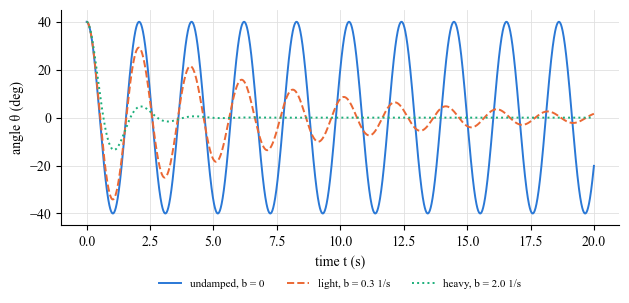

In [5]:
g, L = 9.81, 1.0
T0 = 2*np.pi*np.sqrt(L/g)                   # small-angle period
print(f'T0 = {T0:.4f} s')
R['T0'] = T0

def pendulum(t, y, b):
    """State y = (theta, omega). Signature (t, y) is what solve_ivp expects."""
    theta, omega = y
    return [omega, -b*omega - (g/L)*np.sin(theta)]

def simulate(theta0_deg, b, T=20.0, n=4000):
    te = np.linspace(0, T, n)
    sol = solve_ivp(pendulum, [0, T], [np.deg2rad(theta0_deg), 0.0], args=(b,),
                    t_eval=te, rtol=1e-9, atol=1e-12)
    return sol.t, sol.y[0], sol.y[1]

dampings = [(0.0, 'undamped, b = 0'), (0.3, 'light, b = 0.3 1/s'), (2.0, 'heavy, b = 2.0 1/s')]
runs = {b: simulate(40, b) for b, _ in dampings}
R['dampings'] = [b for b, _ in dampings]

fig, ax = plt.subplots(figsize=(7.2, 2.8))
for (b, lab), c, ls in zip(dampings, C, ['-', '--', ':']):
    tb, th, _ = runs[b]
    ax.plot(tb, np.rad2deg(th), color=c, ls=ls, label=lab)
ax.set_xlabel('time t (s)'); ax.set_ylabel('angle θ (deg)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), fontsize=8, ncol=3); ax.set_ylim(-45, 45)
fig.savefig('figs/fig1_4_damping.png'); plt.show()

## 5. Period against amplitude, by zero crossings and by spectrum

   5 deg: zero crossings 2.007 s, spectrum 2.000 s, ratio 1.000
  45 deg: zero crossings 2.086 s, spectrum 2.069 s, ratio 1.040


  95 deg: zero crossings 2.417 s, spectrum 2.400 s, ratio 1.205
 135 deg: zero crossings 3.065 s, spectrum 3.000 s, ratio 1.528


 175 deg: zero crossings 5.773 s, spectrum 6.001 s, ratio 2.878
   5 deg: elliptic-integral period 2.0070 s (zero crossings differ by 0.000 ms)
  45 deg: elliptic-integral period 2.0863 s (zero crossings differ by 0.000 ms)
  95 deg: elliptic-integral period 2.4174 s (zero crossings differ by 0.000 ms)
 135 deg: elliptic-integral period 3.0652 s (zero crossings differ by 0.000 ms)
 175 deg: elliptic-integral period 5.7728 s (zero crossings differ by 0.001 ms)


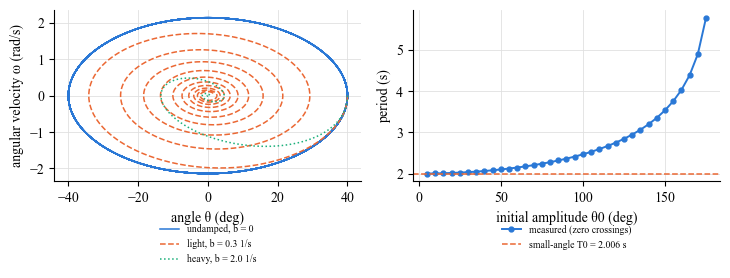

In [6]:
def period_zero_crossings(t, th):
    """Mean spacing of upward zero crossings, each located by linear interpolation."""
    s = np.flatnonzero((th[:-1] < 0) & (th[1:] >= 0))
    tc = t[s] - th[s] * (t[s+1] - t[s]) / (th[s+1] - th[s])
    return float(np.mean(np.diff(tc)))

def period_spectrum(t, th):
    fs2 = 1/(t[1] - t[0])
    A = np.abs(np.fft.rfft(th)); fr = np.fft.rfftfreq(th.size, 1/fs2)
    return float(1/fr[1:][np.argmax(A[1:])])   # skip bin 0, it holds the mean

table_angles = [5, 45, 95, 135, 175]
rows = []
for a in table_angles:
    tt_, th_, _ = simulate(a, 0.0, T=60.0, n=12000)
    pz, ps = period_zero_crossings(tt_, th_), period_spectrum(tt_, th_)
    rows.append(dict(angle=a, zc=pz, spec=ps, ratio=pz/T0))
    print(f'{a:>4} deg: zero crossings {pz:.3f} s, spectrum {ps:.3f} s, ratio {pz/T0:.3f}')
R['period_table'] = rows

# exact period of the undamped pendulum: T = 4 sqrt(L/g) K(k), k = sin(theta0/2), K = complete elliptic integral
from scipy.special import ellipk
for row in rows:
    row['exact'] = float(4*np.sqrt(L/g)*ellipk(np.sin(np.deg2rad(row['angle'])/2)**2))
    print(f"{row['angle']:>4} deg: elliptic-integral period {row['exact']:.4f} s "
          f"(zero crossings differ by {abs(row['zc'] - row['exact'])*1e3:.3f} ms)")

sweep = np.arange(5, 180, 5)
sweep_T = [period_zero_crossings(*simulate(a, 0.0, T=60.0, n=12000)[:2]) for a in sweep]
R['period_sweep'] = dict(angle=sweep.tolist(), period=sweep_T)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 3.0))
for (b, lab), c, ls in zip(dampings, C, ['-', '--', ':']):
    _, th, om = runs[b]
    a1.plot(np.rad2deg(th), om, color=c, ls=ls, lw=1.1, label=lab)
a1.set_xlabel('angle θ (deg)'); a1.set_ylabel('angular velocity ω (rad/s)')
a1.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
a2.plot(sweep, sweep_T, 'o-', color=C[0], ms=3.5, label='measured (zero crossings)')
a2.axhline(T0, color=C[1], ls='--', lw=1.1, label=f'small-angle T0 = {T0:.3f} s')
a2.set_xlabel('initial amplitude θ0 (deg)'); a2.set_ylabel('period (s)')
a2.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
fig.tight_layout(); fig.savefig('figs/fig1_5_phase_period.png'); plt.show()

In [7]:
with open('results.json', 'w') as fh:
    json.dump(R, fh, indent=1)
print('saved results.json')

saved results.json
